# Exercise 1: Perceptron and ADALINE

In [370]:
import pandas as pd
import numpy as np
from sklearn.linear_model import Perceptron, SGDClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score 
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

## Data Preparation

In [372]:
# Loading the generated 21 patterns 
data_wardatul = pd.read_csv('21patterns.csv')

In [373]:
data_wardatul.head()

,p1,p2,p3,p4,p5,p6,p7,p8,p9,p10,...,p55,p56,p57,p58,p59,p60,p61,p62,p63,InputName
0,2,2,2,2,2,0,0,0,2,0,...,2,0,2,2,2,2,2,0,0,D_font1
1,2,2,2,2,2,0,0,2,0,0,...,2,0,2,2,2,2,2,0,0,D_font2
2,2,2,2,2,2,0,0,0,2,0,...,2,0,2,2,2,2,2,0,0,D_font3
3,0,0,2,2,0,0,0,0,0,0,...,2,0,2,2,2,0,2,2,2,A_font1
4,2,2,2,2,2,2,0,0,2,0,...,0,2,2,2,2,2,2,2,0,B_font1


In [374]:
data_wardatul.dtypes

p1            int64
p2            int64
p3            int64
p4            int64
p5            int64
              ...  
p60           int64
p61           int64
p62           int64
p63           int64
InputName    object
Length: 64, dtype: object

In [375]:
# selecting the pixel columns
pixel_columns = data_wardatul.columns[:-1]
pixel_columns.shape

(63,)

In [376]:
# Converting into Bipolar
for col in pixel_columns:
    data_wardatul[col] = data_wardatul[col].astype(int)-1

In [377]:
data_wardatul.head()

,p1,p2,p3,p4,p5,p6,p7,p8,p9,p10,...,p55,p56,p57,p58,p59,p60,p61,p62,p63,InputName
0,1,1,1,1,1,-1,-1,-1,1,-1,...,1,-1,1,1,1,1,1,-1,-1,D_font1
1,1,1,1,1,1,-1,-1,1,-1,-1,...,1,-1,1,1,1,1,1,-1,-1,D_font2
2,1,1,1,1,1,-1,-1,-1,1,-1,...,1,-1,1,1,1,1,1,-1,-1,D_font3
3,-1,-1,1,1,-1,-1,-1,-1,-1,-1,...,1,-1,1,1,1,-1,1,1,1,A_font1
4,1,1,1,1,1,1,-1,-1,1,-1,...,-1,1,1,1,1,1,1,1,-1,B_font1


In [378]:
# Converting target or Inputname into Bipolar (1 if D, -1 if others)
data_wardatul['Target'] = data_wardatul['InputName'].apply(
    lambda name: 1 if name in ['D_font1', 'D_font2', 'D_font3'] else -1
)

In [379]:
data_wardatul.head()

,p1,p2,p3,p4,p5,p6,p7,p8,p9,p10,...,p56,p57,p58,p59,p60,p61,p62,p63,InputName,Target
0,1,1,1,1,1,-1,-1,-1,1,-1,...,-1,1,1,1,1,1,-1,-1,D_font1,1
1,1,1,1,1,1,-1,-1,1,-1,-1,...,-1,1,1,1,1,1,-1,-1,D_font2,1
2,1,1,1,1,1,-1,-1,-1,1,-1,...,-1,1,1,1,1,1,-1,-1,D_font3,1
3,-1,-1,1,1,-1,-1,-1,-1,-1,-1,...,-1,1,1,1,-1,1,1,1,A_font1,-1
4,1,1,1,1,1,1,-1,-1,1,-1,...,1,1,1,1,1,1,1,-1,B_font1,-1


In [380]:
# Drop the InputName
data_wardatul.drop(columns=['InputName'], inplace=True)
data_wardatul.head()

,p1,p2,p3,p4,p5,p6,p7,p8,p9,p10,...,p55,p56,p57,p58,p59,p60,p61,p62,p63,Target
0,1,1,1,1,1,-1,-1,-1,1,-1,...,1,-1,1,1,1,1,1,-1,-1,1
1,1,1,1,1,1,-1,-1,1,-1,-1,...,1,-1,1,1,1,1,1,-1,-1,1
2,1,1,1,1,1,-1,-1,-1,1,-1,...,1,-1,1,1,1,1,1,-1,-1,1
3,-1,-1,1,1,-1,-1,-1,-1,-1,-1,...,1,-1,1,1,1,-1,1,1,1,-1
4,1,1,1,1,1,1,-1,-1,1,-1,...,-1,1,1,1,1,1,1,1,-1,-1


In [381]:
# Determining X and y
X = data_wardatul.drop(columns=['Target']).values
y = data_wardatul['Target'].values
print(X.shape, y.shape)

(21, 63) (21,)


## Classify Input Using Perceptron and ADALINE

In [383]:
# Perceptron
def train_perceptron(X, y):
    model = Perceptron(max_iter=200, eta0=0.1, random_state=42, tol=1e-3)
    model.fit(X, y)
    return model

In [384]:
# ADALINE
def train_adaline(X, y, eta0=0.1, max_iter=200):
    scaler = StandardScaler()
    Xs = scaler.fit_transform(X)
    model = SGDClassifier(loss="squared_error", eta0=eta0,
                          learning_rate="constant", max_iter=max_iter, random_state=42)
    model.fit(Xs, y)
    return model, scaler

In [385]:
# Training data
perceptron = train_perceptron(X, y)
adaline, scaler = train_adaline(X, y)
adaline_tuned, scaler_tuned = train_adaline(X, y, eta0= 0.01, max_iter=500)

In [386]:
# Accuracy Evaluation
def acc(model, X, y, scaler=None):
    if scaler is not None:
        X = scaler.transform(X)
    return (model.predict(X) == y).mean()

acc_p = acc(perceptron, X, y)
acc_a = acc(adaline, X, y, scaler)
acc_at = acc(adaline_tuned, X, y, scaler_tuned)

In [387]:
print("\n=== Accuracy Comparison ===")
print(f"Perceptron (η=0.1,200)            : {acc_p:.2f}")
print(f"ADALINE same config               : {acc_a:.2f}")
print(f"ADALINE tuned config (η=0.01,500) : {acc_at:.2f}")


=== Accuracy Comparison ===
Perceptron (η=0.1,200)            : 1.00
ADALINE same config               : 0.57
ADALINE tuned config (η=0.01,500) : 1.00


In [388]:
# Per-pattern predictions
print("\nPattern | True | Perceptron | ADALINE      | ADALINE tuned")
print("-------------------------------------------------------------")
y_pred_p = perceptron.predict(X)
y_pred_a = adaline.predict(scaler.transform(X))
y_pred_at = adaline_tuned.predict(scaler_tuned.transform(X))
for i in range(len(y)):
    print(f"{i+1:2d}      | {y[i]:+2d}   | {y_pred_p[i]:+2d}         | {y_pred_a[i]:+2d}           | {y_pred_at[i]:+2d}")


Pattern | True | Perceptron | ADALINE      | ADALINE tuned
-------------------------------------------------------------
 1      | +1   | +1         | +1           | +1
 2      | +1   | +1         | +1           | +1
 3      | +1   | +1         | +1           | +1
 4      | -1   | -1         | +1           | -1
 5      | -1   | -1         | +1           | -1
 6      | -1   | -1         | +1           | -1
 7      | -1   | -1         | +1           | -1
 8      | -1   | -1         | -1           | -1
 9      | -1   | -1         | -1           | -1
10      | -1   | -1         | -1           | -1
11      | -1   | -1         | +1           | -1
12      | -1   | -1         | -1           | -1
13      | -1   | -1         | +1           | -1
14      | -1   | -1         | -1           | -1
15      | -1   | -1         | -1           | -1
16      | -1   | -1         | +1           | -1
17      | -1   | -1         | +1           | -1
18      | -1   | -1         | -1           | -1
19      | -1  

In [389]:
# Error analysis
errors_p = [i+1 for i in range(len(y)) if y_pred_p[i] != y[i]]
errors_a = [i+1 for i in range(len(y)) if y_pred_a[i] != y[i]]
errors_at = [i+1 for i in range(len(y)) if y_pred_at[i] != y[i]]
print("\n=== Error Analysis ===")
print(f"Perceptron   : {len(errors_p)} errors    -> patterns [{errors_p if errors_p else 'None'}]")
print(f"ADALINE      : {len(errors_a)} errors    -> patterns {errors_a if errors_a else 'None'}")
print(f"ADALINE tuned: {len(errors_at)} errors    -> patterns [{errors_at if errors_at else 'None'}]")


=== Error Analysis ===
Perceptron   : 0 errors    -> patterns [None]
ADALINE      : 9 errors    -> patterns [4, 5, 6, 7, 11, 13, 16, 17, 19]
ADALINE tuned: 0 errors    -> patterns [None]


## Noise / Missing Tests

In [391]:
def flip_pixels(X, k, seed=42):
    rng = np.random.default_rng(seed)
    Z = X.copy()
    for i in range(len(Z)):
        idx = rng.choice(Z.shape[1], size=k, replace=False)
        Z[i, idx] *= -1
    return Z

In [392]:
def missing_pixels(X, k, seed=42):
    rng = np.random.default_rng(seed)
    Z = X.copy()
    for i in range(len(Z)):
        idx = rng.choice(Z.shape[1], size=k, replace=False)
        Z[i, idx] = 0
    return Z

In [393]:
levels = [5, 10, 15, 20]
flip_acc_p, flip_acc_a, flip_acc_at = [], [], []
miss_acc_p, miss_acc_a, miss_acc_at = [], [], []

In [394]:
print("\n=== Accuracy under noisy inputs ===")
for k in levels:
    X_flip = flip_pixels(X, k)
    X_miss = missing_pixels(X, k)
    flip_acc_p.append(acc(perceptron, X_flip, y))
    flip_acc_a.append(acc(adaline, X_flip, y, scaler))
    flip_acc_at.append(acc(adaline_tuned, X_flip, y, scaler_tuned))
    miss_acc_p.append(acc(perceptron, X_miss, y))
    miss_acc_a.append(acc(adaline, X_miss, y, scaler))
    miss_acc_at.append(acc(adaline_tuned, X_miss, y, scaler_tuned))
    print(f"{k:2d} flipped  -> Perceptron: {flip_acc_p[-1]:.2f}, "
          f"ADALINE: {flip_acc_a[-1]:.2f}, "
          f"TUNED ADALINE: {flip_acc_at[-1]:.2f}")
    
    print(f"{k:2d} missing  -> Perceptron: {miss_acc_p[-1]:.2f}, "
          f"ADALINE: {miss_acc_a[-1]:.2f}, "
          f"TUNED ADALINE: {miss_acc_at[-1]:.2f}")


=== Accuracy under noisy inputs ===
 5 flipped  -> Perceptron: 0.76, ADALINE: 0.57, TUNED ADALINE: 1.00
 5 missing  -> Perceptron: 0.86, ADALINE: 0.52, TUNED ADALINE: 1.00
10 flipped  -> Perceptron: 0.76, ADALINE: 0.48, TUNED ADALINE: 0.90
10 missing  -> Perceptron: 0.76, ADALINE: 0.52, TUNED ADALINE: 1.00
15 flipped  -> Perceptron: 0.90, ADALINE: 0.24, TUNED ADALINE: 0.95
15 missing  -> Perceptron: 0.90, ADALINE: 0.52, TUNED ADALINE: 1.00
20 flipped  -> Perceptron: 0.57, ADALINE: 0.62, TUNED ADALINE: 0.90
20 missing  -> Perceptron: 0.86, ADALINE: 0.57, TUNED ADALINE: 1.00


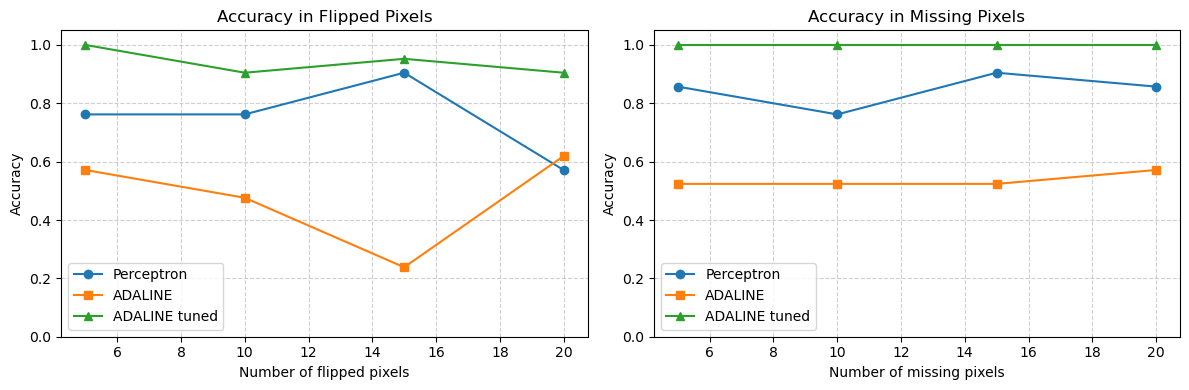

In [421]:
# Plot noise accuracy
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(levels, flip_acc_p, marker="o", label="Perceptron")
plt.plot(levels, flip_acc_a, marker="s", label="ADALINE")
plt.plot(levels, flip_acc_at, marker="^", label="ADALINE tuned")
plt.title("Accuracy in Flipped Pixels")
plt.xlabel("Number of flipped pixels")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()

plt.subplot(1,2,2)
plt.plot(levels, miss_acc_p, marker="o", label="Perceptron")
plt.plot(levels, miss_acc_a, marker="s", label="ADALINE")
plt.plot(levels, miss_acc_at, marker="^", label="ADALINE tuned")
plt.title("Accuracy in Missing Pixels")
plt.xlabel("Number of missing pixels")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()
